# Public geolocation checklist and evidence

Enter latitude and longitude. The backend queries 20 public sources, keeps nearby records separate from confirmed site facts, and stores documents under a folder for that coordinate pair. No credentials, customer uploads, bills or authorization workflows are used.

The table retains the requested four columns plus dates, human-readable titles, evidence links, source coordinates and distance. Preview rows here; CSV/Parquet exports contain the full table.

In [1]:
import json
from pathlib import Path

import polars as pl
from IPython.display import FileLink, Image, display
from API import lookup_site, checklist_table

LATITUDE, LONGITUDE = 42.359, -71.093

site = lookup_site(LATITUDE, LONGITUDE)
table = checklist_table(site)
with pl.Config(tbl_rows=60, tbl_cols=-1, fmt_str_lengths=80):
    display(table.head(60))
print("Sources:", {name: result["status"] for name, result in site["sources"].items()})
print("Site evidence folder:", site["evidence"]["site_directory"])
print("This run:", site["evidence"]["directory"])

display(pl.from_dicts(site["public_coverage"]).select("source", "status", "records", "truncated", "detail"))

checklist item,subcategory_name,subcategory_value,data_source,source_title,fetched_at_utc,source_date,source_date_basis,local_file,file_url,searched_latitude,searched_longitude,source_latitude,source_longitude,source_distance_m,source_location_basis,match_method
str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,str,str
"""Site identity and assessor records""","""address""","""60 VASSAR ST""","""https://services1.arcgis.com/hGdibHYSPO59RG1h/arcgis/rest/services/Massachusetts…","""MassGIS — Massachusetts assessor parcels""","""2026-11-07T21:02:05.270960+00:00""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/parcels.json""",42.359,-71.093,42.359925,-71.090924,199.19,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match""","""point_intersection"""
"""Site identity and assessor records""","""municipality""","""CAMBRIDGE""","""https://arcgisserver.digital.mass.gov/arcgisserver/rest/services/AGOL/Electricit…","""MassGIS — electricity providers by municipality""","""2026-11-07T21:02:05.090783+00:00""",null,"""Source does not supply a record date""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/utilities.json""",42.359,-71.093,null,null,null,"""Municipality-wide record; no site coordinate supplied""","""municipality_containing_point"""
"""Site identity and assessor records""","""state""","""MA""","""https://arcgisserver.digital.mass.gov/arcgisserver/rest/services/AGOL/Electricit…","""MassGIS — electricity providers by municipality""","""2026-11-07T21:02:05.090783+00:00""",null,"""Source does not supply a record date""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/utilities.json""",42.359,-71.093,null,null,null,"""Municipality-wide record; no site coordinate supplied""","""municipality_containing_point"""
"""Site identity and assessor records""","""latitude""","""42.359""","""User-provided coordinates""","""Coordinates supplied by the caller""","""2026-11-07T21:02:07.708892+00:00""",null,"""Caller supplied location; observation date unknown""",null,null,42.359,-71.093,42.359,-71.093,0.0,"""Caller-provided coordinate""","""caller_coordinates"""
"""Site identity and assessor records""","""longitude""","""-71.093""","""User-provided coordinates""","""Coordinates supplied by the caller""","""2026-11-07T21:02:07.708892+00:00""",null,"""Caller supplied location; observation date unknown""",null,null,42.359,-71.093,42.359,-71.093,0.0,"""Caller-provided coordinate""","""caller_coordinates"""
"""Site identity and assessor records""","""parcel_id""","""F_766725_2956445""","""https://services1.arcgis.com/hGdibHYSPO59RG1h/arcgis/rest/services/Massachusetts…","""MassGIS — Massachusetts assessor parcels""","""2026-11-07T21:02:05.270960+00:00""","""2019-04-30""","""Parcel geometry LAST_EDIT; not a title verification date""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/parcels.json""",42.359,-71.093,42.359925,-71.090924,199.19,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match""","""point_intersection"""
"""Site identity and assessor records""","""building_use""","""College or University (Educational Private)""","""https://services1.arcgis.com/hGdibHYSPO59RG1h/arcgis/rest/services/Massachusetts…","""MassGIS — Massachusetts assessor parcels""","""2026-11-07T21:02:05.270960+00:00""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAnd…","""/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/parcels.json"""

Sources: {'utilities': 'ok', 'parcels': 'ok', 'buildings': 'ok', 'lber': 'ok', 'flood': 'ok', 'permits': 'ok', 'electrical_permits': 'ok', 'solar_permits': 'ok', 'public_resources': 'ok', 'elevation': 'ok', 'assessor_records': 'ok', 'municipal_archives': 'unsupported', 'land_records': 'partial', 'lidar': 'ok', 'wetlands': 'no_data', 'environmental': 'ok', 'activity_use_limits': 'ok', 'protected_habitat': 'no_data', 'masscec': 'ok', 'tariffs': 'ok'}
Site evidence folder: /Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000
This run: /Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z


source,status,records,truncated,detail
str,str,i64,bool,str
"""utilities""","""ok""",1,false,null
"""parcels""","""ok""",1,false,null
"""buildings""","""ok""",1,false,null
"""lber""","""ok""",14,false,null
"""flood""","""ok""",1,false,null
…,…,…,…,…
"""environmental""","""ok""",3,false,"""An empty result does not estab…"
"""activity_use_limits""","""ok""",7,false,"""An empty result does not estab…"
"""protected_habitat""","""no_data""",0,false,"""An empty result does not estab…"


## Read the dates correctly

`fetched_at_utc` is the successful retrieval time in UTC. Cached files retain their original fetch time. Failed or uncollected inputs have no successful fetch timestamp. `source_date` describes the underlying record: an assessor fiscal year, survey year, reporting year, permit issue date or verified document date. A year such as `2011` does not imply January 1. `source_date_basis` explains the meaning. The source point and searched point are separate; coordinates and distance are numeric columns. An unknown date stays null; HTTP `Last-Modified` is recorded separately in the file manifest and is never substituted for a document date.

Nearby permits are candidates. A permit's reported status and date do not confirm that it applies to the requested building or that work was completed.


In [2]:
dated = table.filter(pl.col("source_date").is_not_null())
with pl.Config(tbl_cols=-1, fmt_str_lengths=100):
    display(dated.select("subcategory_name", "source_date", "source_date_basis", "fetched_at_utc").head(15))
assert {"source_title", "fetched_at_utc", "source_date", "source_date_basis", "local_file"} <= set(table.columns)
assert table["source_title"].is_not_null().all()


subcategory_name,source_date,source_date_basis,fetched_at_utc
str,str,str,str
"""address""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T21:02:05.270960+00:00"""
"""parcel_id""","""2019-04-30""","""Parcel geometry LAST_EDIT; not a title verification date""","""2026-11-07T21:02:05.270960+00:00"""
"""building_use""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T21:02:05.270960+00:00"""
"""assessor_building_area_sqft""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T21:02:05.270960+00:00"""
"""parcel_attributes[1].OBJECTID""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T21:02:05.270960+00:00"""
…,…,…,…
"""parcel_attributes[1].NO_MATCH""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T21:02:05.270960+00:00"""
"""parcel_attributes[1].TOWN_ID""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T21:02:05.270960+00:00"""
"""parcel_attributes[1].PROP_ID""","""2026""","""Assessor fiscal year FY; not an ownership verification date""","""2026-11-07T21:02:05.270960+00:00"""


## Identify neighboring information

Every row retains the searched latitude/longitude. `source_latitude` and `source_longitude` identify the source record when available; `source_distance_m` is the distance to that representative point. `match_method=within_250m_candidate` flags nearby permit/disclosure candidates. Coordinates and distance alone do not prove a site match.

Parcel/building coordinates are provider polygon centroids, or explicitly labeled bounding-box centers if centroids are unavailable. A centroid may be far from the search point even though the polygon contains it. Municipal references and uncollected inputs have null source coordinates. Elevation uses the requested sampling point, labeled accordingly. Aerial imagery reports the containing tile's center. Selected documents remain ungeoreferenced unless you explicitly supply their coordinates.


In [3]:
location_view = table.select(
    "subcategory_name", "subcategory_value", "searched_latitude", "searched_longitude",
    "source_latitude", "source_longitude", "source_distance_m", "source_location_basis", "match_method",
)
with pl.Config(tbl_cols=-1, fmt_str_lengths=80):
    display(location_view.filter(pl.col("subcategory_name").is_in(["address", "mapped_building_id", "permit_history[1].address"])))
    display(location_view.filter(pl.col("match_method") == "within_250m_candidate").head(12))
assert table["searched_latitude"].eq(LATITUDE).all()
assert table["searched_longitude"].eq(LONGITUDE).all()


subcategory_name,subcategory_value,searched_latitude,searched_longitude,source_latitude,source_longitude,source_distance_m,source_location_basis,match_method
str,str,f64,f64,f64,f64,f64,str,str
"""address""","""60 VASSAR ST""",42.359,-71.093,42.359925,-71.090924,199.19,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match""","""point_intersection"""
"""mapped_building_id""","""233661_901110""",42.359,-71.093,42.360085,-71.091363,180.66,"""Provider polygon centroid in WGS84; not a meter or neighboring-site match""","""point_intersection"""
"""permit_history[1].address""","""127 Massachusetts Ave, Cambridge, MA 02142""",42.359,-71.093,42.360299,-71.094044,167.99,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""


subcategory_name,subcategory_value,searched_latitude,searched_longitude,source_latitude,source_longitude,source_distance_m,source_location_basis,match_method
str,str,f64,f64,f64,f64,f64,str,str
"""public_service_relationships[1].permit_id""","""1214373""",42.359,-71.093,42.357347,-71.09452,222.22,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""
"""public_service_relationships[1].address""","""320 Memorial Dr, Cambridge, MA 02139""",42.359,-71.093,42.357347,-71.09452,222.22,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""
"""public_service_relationships[1].parcel_id""","""58-95""",42.359,-71.093,42.357347,-71.09452,222.22,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""
"""public_service_relationships[1].parcel_relation""","""nearby/unmatched parcel""",42.359,-71.093,42.357347,-71.09452,222.22,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""
"""public_service_relationships[1].existing_meter_count""","""2""",42.359,-71.093,42.357347,-71.09452,222.22,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""
…,…,…,…,…,…,…,…,…
"""public_service_relationships[2].permit_id""","""1213648""",42.359,-71.093,42.360994,-71.092813,222.25,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""
"""public_service_relationships[2].address""","""60 Vassar St, Unit Rear, Cambridge, MA 02142""",42.359,-71.093,42.360994,-71.092813,222.25,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""
"""public_service_relationships[2].parcel_relation""","""nearby/unmatched parcel""",42.359,-71.093,42.360994,-71.092813,222.25,"""Provider-reported record coordinates (WGS84)""","""within_250m_candidate"""


## Expanded public sources

All raw non-null LBER attributes are exposed for 2024 and 2025, including fuels, EUI, generation and reporting boundaries when published. MassCEC PTS equipment records are municipality context: the report does not identify a street-level facility. Tariff rows quote public components and preserve page references and effective dates; they do not select an applicable customer rate. Environmental hits are screening candidates, and empty results do not establish clearance.

In [4]:
public_evidence = table.filter(
    pl.col("subcategory_name").str.contains("electrical_permit_candidates|annual_energy_candidates|tariff_candidates|masscec_context|environmental_candidates")
)
with pl.Config(tbl_cols=-1, fmt_str_lengths=100):
    display(public_evidence.select("subcategory_name", "subcategory_value", "source_title", "source_date", "match_method").head(35))

print("Imagery coverage:", site["evidence"]["imagery_coverage"])
print("Lidar sample range:", site["sources"]["lidar"].get("summary"))

subcategory_name,subcategory_value,source_title,source_date,match_method
str,str,str,str,str
"""tariff_candidates[1].component_text""","""Customer Charge: As per M.D.P.U. No. 1 as in effect from time to time.""","""Utility-published Cambridge G-3""","""2025-01-01""","""utility_area_schedule_candidate"""
"""tariff_candidates[1].amounts_raw""","""[]""","""Utility-published Cambridge G-3""","""2025-01-01""","""utility_area_schedule_candidate"""
"""tariff_candidates[1].cross_reference""","""As per M.D.P.U. No. 1 as in effect from time to time.""","""Utility-published Cambridge G-3""","""2025-01-01""","""utility_area_schedule_candidate"""
"""tariff_candidates[1].rate_assignment""","""unassigned public schedule mention; inspect columns and applicability""","""Utility-published Cambridge G-3""","""2025-01-01""","""utility_area_schedule_candidate"""
"""tariff_candidates[1].url""","""https://www.eversource.com/content/docs/default-source/rates-tariffs/ma-electric/21-tariff-ma.pdf""","""Utility-published Cambridge G-3""","""2025-01-01""","""utility_area_schedule_candidate"""
…,…,…,…,…
"""tariff_candidates[3].url""","""https://www.eversource.com/content/docs/default-source/rates-tariffs/ma-electric/21-tariff-ma.pdf""","""Utility-published Cambridge G-3""","""2025-01-01""","""utility_area_schedule_candidate"""
"""tariff_candidates[3].source_title""","""Utility-published Cambridge G-3""","""Utility-published Cambridge G-3""","""2025-01-01""","""utility_area_schedule_candidate"""
"""tariff_candidates[3].page""","""1""","""Utility-published Cambridge G-3""","""2025-01-01""","""utility_area_schedule_candidate"""


Imagery coverage: {'bbox_wgs84': [-71.0945980050631, 42.3575433534042, -71.0873567948307, 42.362590888197], 'zoom': 17, 'tile_count': 9}
Lidar sample range: {'min_sample_elevation_m': -0.008468628, 'max_sample_elevation_m': 3.108764648}


## Open downloaded files

The Git-ignored `data/evidence/<latitude>_<longitude>/` folder contains **all files for that search location**. `files/` holds downloads; `runs/<timestamp>/` holds immutable snapshots, a full JSON response and CSV/Parquet tables. A root `manifest.json` and `README.md` identify the latest run and link its evidence. Downloads include one 2025 MassGIS aerial tile, the municipal portal page and up to three public permit detail records. Public document links exposed by those records are downloaded when available. Each file has its source URL, readable title, fetch date, available source date and SHA-256 hash.

The aerial tile is map context, not a current site photograph. Files remain evidence to review, rather than verified electrical ratings or current as-built drawings. Download errors appear in `site["evidence"]["errors"]` and as table rows.


kind,source_title,status,source_date,fetched_at_utc,local_file
str,str,str,str,str,str
"""source_snapshot""","""MassGIS — electricity providers by municipality""","""ok""",null,"""2026-11-07T21:02:05.090783+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""source_snapshot""","""MassGIS — Massachusetts assessor parcels""","""ok""",null,"""2026-11-07T21:02:05.270960+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""source_snapshot""","""MassGIS — building structures and roof outlines""","""ok""",null,"""2026-11-07T21:02:05.367159+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""source_snapshot""","""Massachusetts DOER — multi-year building energy disclosures""","""ok""",null,"""2026-11-07T21:02:05.462278+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""source_snapshot""","""FEMA — National Flood Hazard Layer""","""ok""",null,"""2026-11-07T21:02:05.877320+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
…,…,…,…,…,…
"""lidar_raster""","""MassGIS lidar DEM — parcel envelope raster""","""ok""",null,"""2026-11-07T20:40:08.377934+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""reference_page""","""CAMBRIDGE — municipal permit portal""","""ok""",null,"""2026-11-07T20:11:39.374500+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"
"""permit_detail""","""Cambridge — Electrical permit 1234675""","""ok""","""2026-10-30""","""2026-11-07T20:11:40.034743+00:00""","""/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data…"


/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/manifest.json

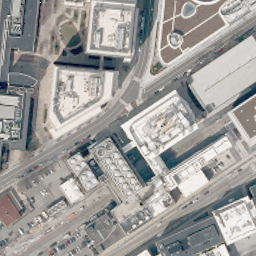

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/utilities.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/parcels.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/buildings.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/lber.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/flood.json

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/permits.json

... (63 outputs left out)

checklist_csv


/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/checklist.csv

checklist_parquet


/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.359000_-71.093000/runs/20261107T210207709012Z/checklist.parquet

In [5]:
files = pl.from_dicts(site["evidence"]["files"], infer_schema_length=None)
with pl.Config(tbl_cols=-1, fmt_str_lengths=100):
    display(files.select("kind", "source_title", "status", "source_date", "fetched_at_utc", "local_file"))
assert all(Path(asset["local_file"]).is_file() for asset in site["evidence"]["files"] if asset["status"] == "ok")
display(FileLink(str(Path(site["evidence"]["manifest_file"]).relative_to(Path.cwd()))))
aerial = next((asset for asset in site["evidence"]["files"] if asset["kind"] == "aerial_image" and asset["status"] == "ok"), None)
if aerial:
    display(Image(filename=aerial["local_file"]))

for asset in site["evidence"]["files"]:
    if asset["status"] == "ok":
        display(FileLink(str(Path(asset["local_file"]).relative_to(Path.cwd()))))

display(FileLink(str(Path(site["evidence"]["index_file"]).relative_to(Path.cwd()))))
for name, export in site["evidence"]["exports"].items():
    print(name)
    display(FileLink(str(Path(export["local_file"]).relative_to(Path.cwd()))))


## Automatic municipal document discovery — another geolocation

This Northampton point demonstrates public assessor-card and archive discovery using coordinates alone. Parcel lookup supplies the address for an anonymous archive search. The response preserves full-text candidates, prioritizes address matches in document titles for downloads, and exposes result/download limits. A document mentioning an address may describe a neighboring project. Native PDF text is extracted for up to 80 pages; image-only PDFs and truncation remain explicit. No OCR is performed.

In [6]:
archive_example = lookup_site(
    42.317749905435555, -72.63151759306088,
    sources=["assessor_records", "municipal_archives"],
)
archive_table = checklist_table(archive_example)
archive_files = [f for f in archive_example["evidence"]["files"] if f["kind"] == "document"]
display(pl.from_dicts([{
    "title": f["source_title"], "status": f["status"], "pages": f.get("page_count"),
    "pages_examined": f.get("pages_examined"), "text_status": f.get("text_status"),
    "local_file": f.get("local_file"),
} for f in archive_files], infer_schema_length=None))
assert archive_example["sources"]["municipal_archives"]["records"], "No archive candidates returned; inspect source status and detail."
for f in archive_files:
    if f["status"] == "ok": display(FileLink(str(Path(f["local_file"]).relative_to(Path.cwd()))))

Rotated text discovered. Output will be incomplete.


Rotated text discovered. Output will be incomplete.


Rotated text discovered. Output will be incomplete.


Rotated text discovered. Output will be incomplete.


Rotated text discovered. Output will be incomplete.


Rotated text discovered. Output will be incomplete.


... (26 outputs left out)

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.317750_-72.631518/files/main-street-202-pdf-f72bb08d51ef2b276219-515dea191a1f9916.pdf

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.317750_-72.631518/files/final-stormwater-report-05-11-2017-354dd737351ce9e89ee6-e0c195f15e4dbccb.pdf

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.317750_-72.631518/files/request-amended-ooc-2017-electronic-b8b5307f0ac6e518d2c8-4fd25dfe737d9160.pdf

/Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/evidence/42.317750_-72.631518/files/609286-eecc-with-appendicies-a-b-c-9e84570923e07128d00c-6b510b937346d192.pdf

## Save and debug

CSV is convenient for Excel; Parquet preserves nulls and numeric coordinate types. `local_file` points to the backend computer. `file_url` is relative to the API base URL, for example `http://127.0.0.1:8002/evidence/...`. Notebook links below use Jupyter-relative paths so they work when launched from this repository root.


In [7]:
output_dir = Path("data/processed/site_checklist")
output_dir.mkdir(parents=True, exist_ok=True)
table.write_csv(output_dir / "checklist.csv")
table.write_parquet(output_dir / "checklist.parquet")
(output_dir / "site.json").write_text(json.dumps(site, indent=2))
archive_table.write_csv(output_dir / "archive_example_checklist.csv")
print("Saved", table.shape, "to", output_dir.resolve())
errors = table.filter(pl.col("subcategory_name").str.ends_with(".error"))
if errors.height:
    with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=500):
        display(errors)
else:
    print("No retrieval errors for this lookup.")


Saved (4566, 17) to /Users/juandiegopalaciosgodoy/Documents/MITEnergyAndClimateHack2026/MITEnergyAndClimateHack2026/data/processed/site_checklist
No retrieval errors for this lookup.


The same dated table is available over HTTP after starting `uv run uvicorn API.server:app --reload --port 8002`:

```python
import requests
response = requests.get(
    "http://127.0.0.1:8002/site/table",
    params={"latitude": LATITUDE, "longitude": LONGITUDE}, timeout=180,
)
response.raise_for_status()
table = pl.from_dicts(response.json())
```

Use `download_evidence=False` in Python or `download_evidence=false` over HTTP to skip the exported evidence packet (source files needed for extraction are still cached). Use `refresh=True` / `refresh=true` to redownload cached files. Provider JSON queries are live on every call. The MVP needs no API keys.
